Dataset shape: (5010, 18)


,name,main_category,sub_category,image,link,no_of_ratings,discount_price,actual_price,review_rating,review_text,discount_price_missing,actual_price_missing,review_count_missing,review_text_missing,price_available,discount_amount,discount_percent,detected_category
0,"redmi 10 power (power black, 8gb ram, 128gb st...","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/81eM15lVcJ...,https://www.amazon.in/Redmi-Power-Black-128GB-...,965.0,10999.0,18999.0,3.0,NOTE:,0,0,0,0,1,8000.0,42.107479,Smartphones
1,"oneplus nord ce 2 lite 5g (blue tide, 6gb ram,...","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/71AvQd3Vzq...,https://www.amazon.in/OnePlus-Nord-Lite-128GB-...,113956.0,18999.0,19999.0,1.0,Very bad experience with this device xr phone....,0,0,0,0,1,1000.0,5.000250,Smartphones
2,oneplus bullets z2 bluetooth wireless in ear e...,"tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/51UhwaQXCp...,https://www.amazon.in/Oneplus-Bluetooth-Wirele...,90304.0,1999.0,2299.0,5.0,Amazing phone with amazing camera coming from ...,0,0,0,0,1,300.0,13.049152,Headphones and Earphones
3,"samsung galaxy m33 5g (mystique green, 6gb, 12...","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/81I3w4J6yj...,https://www.amazon.in/Samsung-Mystique-Storage...,24863.0,15999.0,24999.0,1.0,So I got the device XR just today. The product...,0,0,0,0,1,9000.0,36.001440,Smartphones
4,"oneplus nord ce 2 lite 5g (black dusk, 6gb ram...","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/71V--WZVUI...,https://www.amazon.in/OnePlus-Nord-Black-128GB...,113956.0,18999.0,19999.0,5.0,I've been an android user all my life until I ...,0,0,0,0,1,1000.0,5.000250,Smartphones


,count,mean,std,min,25%,50%,75%,max,median,variance,skewness,kurtosis
discount_price,4740.0,3078.191,8564.866,36.000,299.000,649.000,1699.000,127999.000,649.000,7.335693e+07,6.735,64.917
actual_price,4979.0,5226.882,11861.096,35.000,835.000,1499.000,3999.000,149999.000,1499.000,1.406856e+08,5.600,42.577
review_rating,5010.0,4.488,1.086,1.000,4.000,5.000,5.000,5.000,5.000,1.179000e+00,-2.334,4.416
no_of_ratings,4958.0,13260.089,34803.226,1.000,509.250,2321.000,9812.750,437651.000,2321.000,1.211265e+09,6.083,49.532
discount_percent,4740.0,51.882,21.985,0.004,35.035,55.576,70.023,97.889,55.576,4.833600e+02,-0.425,-0.793


,Feature,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,discount_price,-1801.00,3799.00,633,12.63
1,actual_price,-3911.00,8745.00,632,12.61
2,review_rating,2.50,6.50,406,8.10
3,no_of_ratings,-13446.00,23768.00,681,13.59
4,discount_percent,-17.45,122.51,0,0.00


HIGH DISCOUNT GROUP
Count: 2370
Mean rating: 4.496624472573839

LOW DISCOUNT GROUP
Count: 2370
Mean rating: 4.483966244725738

Levene test p-value: 0.6873706777750351

T-TEST RESULTS
T-statistic: 0.4024504845149637
P-value: 0.6873706777763988
Fail to reject H0
There is insufficient evidence of a difference.


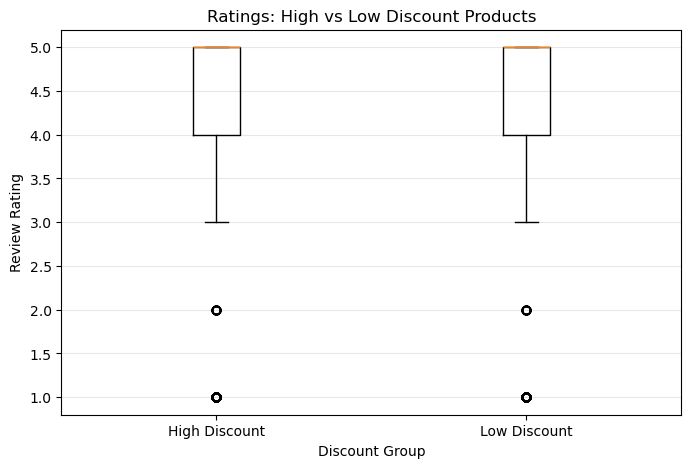

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import (
    shapiro,
    spearmanr,
    pearsonr,
    mannwhitneyu
)

import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("../electronics_eda_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())

numerical_columns = [
    "discount_price",
    "actual_price",
    "review_rating",
    "no_of_ratings",
    "discount_percent"
]

available_columns = [
    col for col in numerical_columns
    if col in df.columns
]

summary = df[available_columns].describe().T

summary["median"] = df[available_columns].median()
summary["variance"] = df[available_columns].var()
summary["skewness"] = df[available_columns].skew()
summary["kurtosis"] = df[available_columns].kurtosis()

display(summary.round(3))

def calculate_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = data[
        (data[column] < lower) |
        (data[column] > upper)
    ]

    return {
        "Feature": column,
        "Lower Limit": lower,
        "Upper Limit": upper,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (
            len(outliers) / len(data)
        ) * 100
    }


outlier_results = pd.DataFrame([
    calculate_outliers(df, col)
    for col in available_columns
])

display(outlier_results.round(2))

from scipy.stats import ttest_ind, levene

# Divide products using median discount
median_discount = df["discount_percent"].median()

high_discount = df[
    df["discount_percent"] > median_discount
]["review_rating"].dropna()

low_discount = df[
    df["discount_percent"] <= median_discount
]["review_rating"].dropna()

# Calculate group statistics
print("HIGH DISCOUNT GROUP")
print("Count:", len(high_discount))
print("Mean rating:", high_discount.mean())

print("\nLOW DISCOUNT GROUP")
print("Count:", len(low_discount))
print("Mean rating:", low_discount.mean())

# Test equality of variances
levene_stat, levene_p = levene(
    high_discount,
    low_discount
)

print("\nLevene test p-value:", levene_p)

# Independent Welch's t-test
t_stat, p_value = ttest_ind(
    high_discount,
    low_discount,
    equal_var=False
)

print("\nT-TEST RESULTS")
print("T-statistic:", t_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("There is a statistically significant difference.")
else:
    print("Fail to reject H0")
    print("There is insufficient evidence of a difference.")

plt.figure(figsize=(8, 5))

plt.boxplot(
    [high_discount, low_discount],
    tick_labels=["High Discount", "Low Discount"]
)

plt.title("Ratings: High vs Low Discount Products")
plt.xlabel("Discount Group")
plt.ylabel("Review Rating")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [4]:
alpha = 0.05
p_value = 0.68737067777763988

print("SIGNIFICANCE LEVEL:", alpha)
print("P-VALUE:", p_value)

if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

print("\nTYPE I ERROR:")
print("Rejecting a true null hypothesis.")

print("\nTYPE II ERROR:")
print("Failing to reject a false null hypothesis.")

SIGNIFICANCE LEVEL: 0.05
P-VALUE: 0.6873706777776398
Fail to reject the null hypothesis.

TYPE I ERROR:
Rejecting a true null hypothesis.

TYPE II ERROR:
Failing to reject a false null hypothesis.
